In [16]:
import torch
import sklearn
import numpy
import matplotlib

print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
scikit-learn: 1.6.1
GPU available: False


In [17]:
%%writefile config.json
{
  "seed": 42,
  "batch_size": 64,
  "epochs": 80,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "dropout": 0.3,
  "patience": 10,
  "occlusion_sizes": [0, 1, 2, 3]
}

Overwriting config.json


In [18]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

cfg = json.loads(Path("config.json").read_text())
out = Path("results")
out.mkdir(exist_ok=True)

seed = cfg["seed"]
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

digits = load_digits()

# Normalize ด้วยขอบเขตค่าที่ทราบจากคำอธิบายข้อมูล
# ไม่ได้คำนวณค่าสถิติจาก test
X = (digits.images / 16.0).astype(np.float32)
y = digits.target.astype(np.int64)

indices = np.arange(len(y))

train_idx, remaining_idx = train_test_split(
    indices,
    test_size=0.4,
    random_state=seed,
    stratify=y
)

val_idx, test_idx = train_test_split(
    remaining_idx,
    test_size=0.5,
    random_state=seed,
    stratify=y[remaining_idx]
)

assert not set(train_idx) & set(val_idx)
assert not set(train_idx) & set(test_idx)
assert not set(val_idx) & set(test_idx)

np.savez(
    out / "split_indices.npz",
    train=train_idx,
    val=val_idx,
    test=test_idx
)

for name, idx in [
    ("train", train_idx),
    ("validation", val_idx),
    ("test", test_idx)
]:
    print(name, len(idx))
    print("class counts:", np.bincount(y[idx], minlength=10))

Device: cpu
train 1078
class counts: [107 109 106 110 109 109 109 107 104 108]
validation 359
class counts: [36 36 36 36 36 36 36 36 35 36]
test 360
class counts: [35 37 35 37 36 37 36 36 35 36]


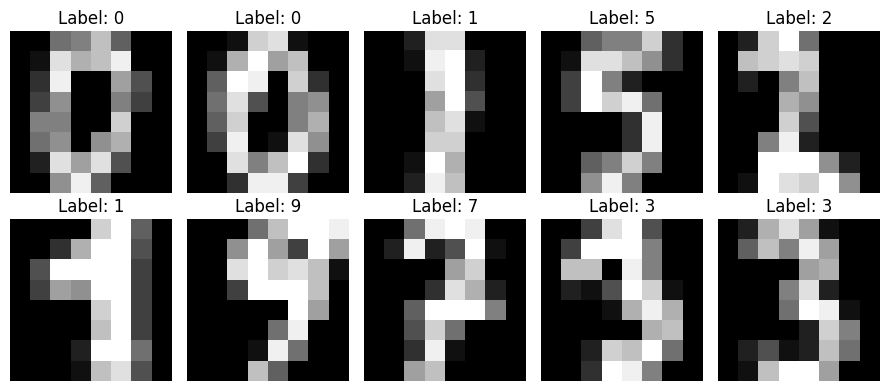

In [19]:
fig, axes = plt.subplots(2, 5, figsize=(9, 4))

for ax, idx in zip(axes.ravel(), train_idx[:10]):
    ax.imshow(X[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y[idx]}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(out / "train_examples.png", dpi=160)
plt.show()

In [20]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Flatten(),

            nn.Linear(32 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

model = SmallCNN(cfg["dropout"]).to(device)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

SmallCNN(
  (network): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Flatten(start_dim=1, end_dim=-1)
    (6): Linear(in_features=512, out_features=64, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 38282


In [21]:
import copy
import csv

train_dataset = TensorDataset(
    torch.from_numpy(X[train_idx, None]),
    torch.from_numpy(y[train_idx])
)

generator = torch.Generator().manual_seed(seed)

train_loader = DataLoader(
    train_dataset,
    batch_size=cfg["batch_size"],
    shuffle=True,
    generator=generator,
    num_workers=0
)

val_x = torch.from_numpy(X[val_idx, None]).to(device)
val_y = torch.from_numpy(y[val_idx]).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=cfg["learning_rate"],
    weight_decay=cfg["weight_decay"]
)

history = []
best_val_loss = float("inf")
best_state = None
best_epoch = 0
stale_epochs = 0

for epoch in range(1, cfg["epochs"] + 1):
    model.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        logits = model(batch_x)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(batch_y)
        correct += (
            logits.argmax(dim=1) == batch_y
        ).sum().item()
        total += len(batch_y)

    model.eval()

    with torch.no_grad():
        val_logits = model(val_x)
        val_loss = criterion(val_logits, val_y).item()
        val_accuracy = (
            val_logits.argmax(dim=1) == val_y
        ).float().mean().item()

    row = {
        "epoch": epoch,
        "train_loss": loss_sum / total,
        "val_loss": val_loss,
        "train_accuracy": correct / total,
        "val_accuracy": val_accuracy
    }
    history.append(row)

    print(
        f"Epoch {epoch:03d} | "
        f"train loss={row['train_loss']:.4f} | "
        f"val loss={val_loss:.4f} | "
        f"val accuracy={val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        stale_epochs = 0
    else:
        stale_epochs += 1

    if stale_epochs >= cfg["patience"]:
        print("Early stopping")
        break

assert best_state is not None
model.load_state_dict(best_state)

# เก็บน้ำหนักไว้บน CPU เพื่อโหลดสะดวกทั้ง CPU/GPU
cpu_state = {
    key: value.detach().cpu()
    for key, value in best_state.items()
}

torch.save(
    {
        "state_dict": cpu_state,
        "config": cfg,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    },
    out / "best_model.pt"
)

with open(out / "history.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(history[0]))
    writer.writeheader()
    writer.writerows(history)

print("Selected epoch:", best_epoch)

Epoch 001 | train loss=2.2737 | val loss=2.2159 | val accuracy=0.4791
Epoch 002 | train loss=2.1279 | val loss=1.9679 | val accuracy=0.6267
Epoch 003 | train loss=1.7330 | val loss=1.3611 | val accuracy=0.7632
Epoch 004 | train loss=1.1559 | val loss=0.7561 | val accuracy=0.8301
Epoch 005 | train loss=0.7569 | val loss=0.4866 | val accuracy=0.8747
Epoch 006 | train loss=0.5585 | val loss=0.3707 | val accuracy=0.8969
Epoch 007 | train loss=0.4318 | val loss=0.2901 | val accuracy=0.9053
Epoch 008 | train loss=0.3865 | val loss=0.2388 | val accuracy=0.9276
Epoch 009 | train loss=0.3364 | val loss=0.2157 | val accuracy=0.9471
Epoch 010 | train loss=0.2895 | val loss=0.1814 | val accuracy=0.9526
Epoch 011 | train loss=0.2529 | val loss=0.1557 | val accuracy=0.9526
Epoch 012 | train loss=0.2453 | val loss=0.1465 | val accuracy=0.9610
Epoch 013 | train loss=0.2245 | val loss=0.1474 | val accuracy=0.9554
Epoch 014 | train loss=0.1896 | val loss=0.1205 | val accuracy=0.9554
Epoch 015 | train lo

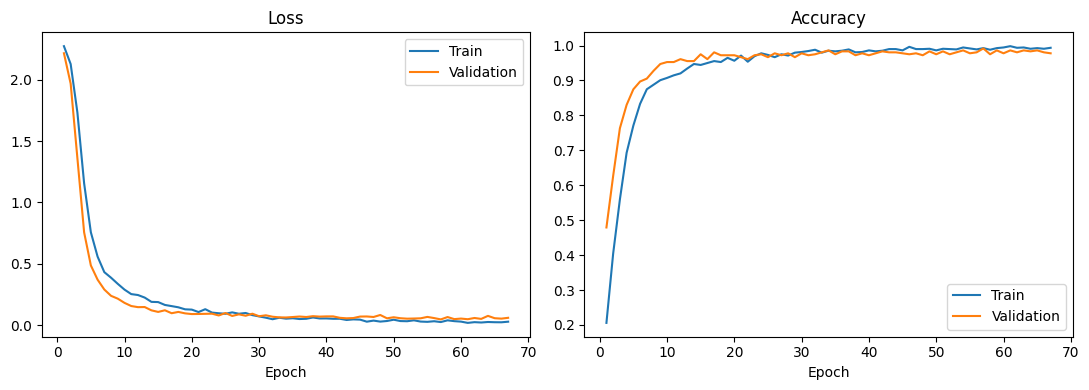

In [22]:
epochs = [row["epoch"] for row in history]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    epochs, [r["train_loss"] for r in history],
    label="Train"
)
axes[0].plot(
    epochs, [r["val_loss"] for r in history],
    label="Validation"
)
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(
    epochs, [r["train_accuracy"] for r in history],
    label="Train"
)
axes[1].plot(
    epochs, [r["val_accuracy"] for r in history],
    label="Validation"
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(out / "learning_curves.png", dpi=160)
plt.show()

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
import joblib

flat_train = X[train_idx].reshape(len(train_idx), -1)

majority = DummyClassifier(strategy="most_frequent")
majority.fit(flat_train, y[train_idx])

logistic = LogisticRegression(
    C=1.0,
    max_iter=3000,
    random_state=seed
)
logistic.fit(flat_train, y[train_idx])

joblib.dump(
    {"majority": majority, "logistic": logistic},
    out / "baselines.joblib"
)

['results/baselines.joblib']

Majority mask = 0 accuracy = 0.1028 macro_f1 = 0.0186
LogisticRegression mask = 0 accuracy = 0.9556 macro_f1 = 0.9555
CNN mask = 0 accuracy = 0.9833 macro_f1 = 0.9832
Majority mask = 1 accuracy = 0.1028 macro_f1 = 0.0186
LogisticRegression mask = 1 accuracy = 0.9056 macro_f1 = 0.9026
CNN mask = 1 accuracy = 0.8944 macro_f1 = 0.8916
Majority mask = 2 accuracy = 0.1028 macro_f1 = 0.0186
LogisticRegression mask = 2 accuracy = 0.7667 macro_f1 = 0.7335
CNN mask = 2 accuracy = 0.7139 macro_f1 = 0.6535
Majority mask = 3 accuracy = 0.1028 macro_f1 = 0.0186
LogisticRegression mask = 3 accuracy = 0.5583 macro_f1 = 0.4769
CNN mask = 3 accuracy = 0.4556 macro_f1 = 0.3866
              precision    recall  f1-score   support

           0     1.0000    0.9714    0.9855        35
           1     0.9730    0.9730    0.9730        37
           2     0.9722    1.0000    0.9859        35
           3     1.0000    1.0000    1.0000        37
           4     0.9722    0.9722    0.9722        36
       

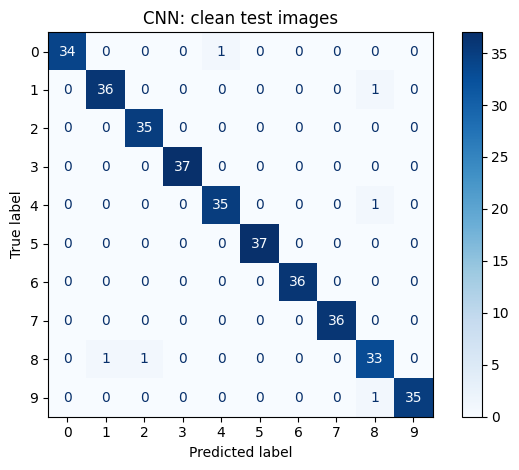

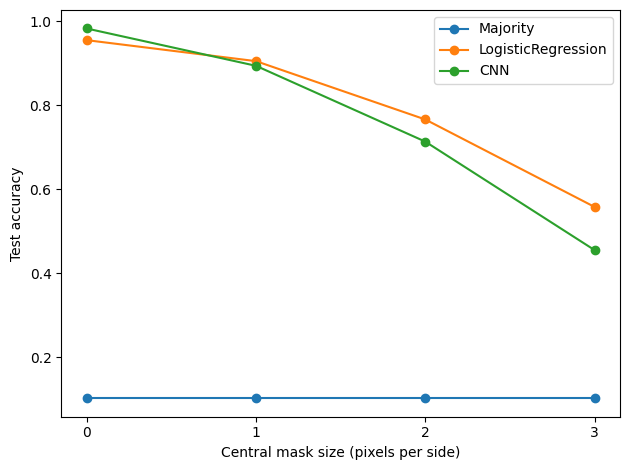

In [24]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# โหลด checkpoint ที่เลือกด้วย validation
checkpoint = torch.load(
    out / "best_model.pt",
    map_location="cpu",
    weights_only=True
)

eval_model = SmallCNN(
    checkpoint["config"]["dropout"]
).to(device)

eval_model.load_state_dict(checkpoint["state_dict"])
eval_model.eval()

def occlude(images, size):
    result = images.copy()

    if size > 0:
        start = (8 - size) // 2
        result[
            :, start:start + size, start:start + size
        ] = 0.0

    return result

def cnn_predict(images):
    with torch.no_grad():
        tensor = torch.from_numpy(
            images[:, None]
        ).to(device)

        return (
            eval_model(tensor)
            .argmax(dim=1)
            .cpu()
            .numpy()
        )

test_images = X[test_idx]
test_labels = y[test_idx]

metric_rows = []
prediction_rows = []

for size in cfg["occlusion_sizes"]:
    images = occlude(test_images, size)
    flat = images.reshape(len(images), -1)

    predictions = {
        "Majority": majority.predict(flat),
        "LogisticRegression": logistic.predict(flat),
        "CNN": cnn_predict(images)
    }

    for name, pred in predictions.items():
        metric_rows.append({
            "model": name,
            "occlusion_size": size,
            "accuracy": accuracy_score(test_labels, pred),
            "macro_f1": f1_score(
                test_labels, pred,
                labels=list(range(10)),
                average="macro",
                zero_division=0
            )
        })

        for original_idx, target, guessed in zip(
            test_idx, test_labels, pred
        ):
            prediction_rows.append({
                "dataset_index": int(original_idx),
                "occlusion_size": size,
                "model": name,
                "target": int(target),
                "prediction": int(guessed)
            })

for filename, rows in [
    ("metrics.csv", metric_rows),
    ("predictions.csv", prediction_rows)
]:
    with open(out / filename, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

for row in metric_rows:
    print(
        row["model"],
        "mask =", row["occlusion_size"],
        "accuracy =", round(row["accuracy"], 4),
        "macro_f1 =", round(row["macro_f1"], 4)
    )

clean_pred = cnn_predict(test_images)

print(classification_report(
    test_labels,
    clean_pred,
    labels=list(range(10)),
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    test_labels,
    clean_pred,
    labels=list(range(10)),
    cmap="Blues"
)
plt.title("CNN: clean test images")
plt.tight_layout()
plt.savefig(out / "confusion_matrix.png", dpi=160)
plt.show()

for name in ["Majority", "LogisticRegression", "CNN"]:
    rows = [r for r in metric_rows if r["model"] == name]
    plt.plot(
        [r["occlusion_size"] for r in rows],
        [r["accuracy"] for r in rows],
        marker="o",
        label=name
    )

plt.xlabel("Central mask size (pixels per side)")
plt.ylabel("Test accuracy")
plt.xticks(cfg["occlusion_sizes"])
plt.legend()
plt.tight_layout()
plt.savefig(out / "occlusion_accuracy.png", dpi=160)
plt.show()

In [25]:
import platform
import sklearn
import matplotlib

environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "joblib": joblib.__version__,
    "device": str(device),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

(out / "environment.json").write_text(
    json.dumps(environment, indent=2)
)

Path("requirements.txt").write_text(
    f"torch=={torch.__version__.split('+')[0]}\n"
    f"numpy=={np.__version__}\n"
    f"scikit-learn=={sklearn.__version__}\n"
    f"matplotlib=={matplotlib.__version__}\n"
    f"joblib=={joblib.__version__}\n"
)

print("Saved environment and requirements")

Saved environment and requirements


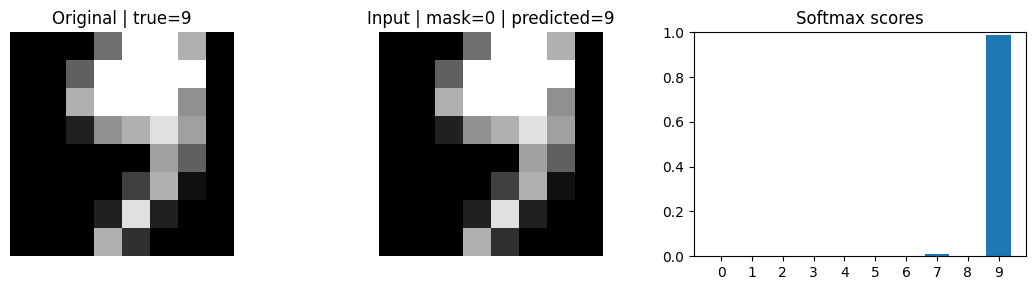

Dataset index: 1562
Correct: True


In [26]:
def demo(test_position, mask_size=0):
    if not 0 <= test_position < len(test_idx):
        raise ValueError("test_position must be 0..359")

    original = test_images[test_position:test_position + 1]
    processed = occlude(original, mask_size)

    with torch.no_grad():
        tensor = torch.from_numpy(
            processed[:, None]
        ).to(device)

        probabilities = (
            eval_model(tensor)
            .softmax(dim=1)[0]
            .cpu()
            .numpy()
        )

    prediction = int(probabilities.argmax())
    target = int(test_labels[test_position])

    fig, axes = plt.subplots(1, 3, figsize=(11, 3))

    axes[0].imshow(original[0], cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(f"Original | true={target}")
    axes[0].axis("off")

    axes[1].imshow(processed[0], cmap="gray", vmin=0, vmax=1)
    axes[1].set_title(
        f"Input | mask={mask_size} | predicted={prediction}"
    )
    axes[1].axis("off")

    axes[2].bar(range(10), probabilities)
    axes[2].set_xticks(range(10))
    axes[2].set_ylim(0, 1)
    axes[2].set_title("Softmax scores")

    plt.tight_layout()
    plt.show()

    print("Dataset index:", int(test_idx[test_position]))
    print("Correct:", prediction == target)

# ตัวอย่างการเรียก
demo(test_position=0, mask_size=0)

Success example


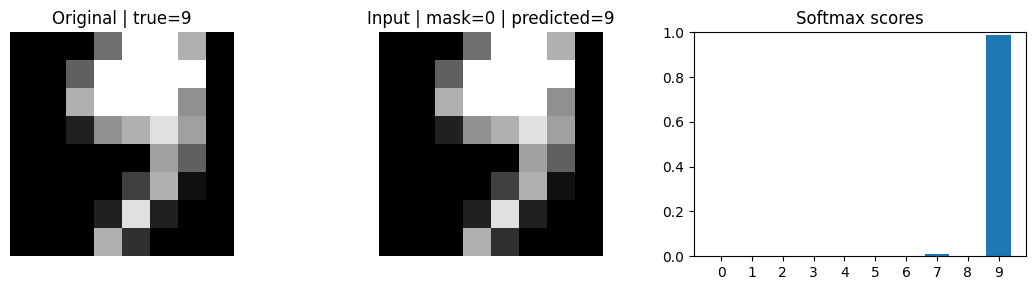

Dataset index: 1562
Correct: True
Failure example
Mask size: 0


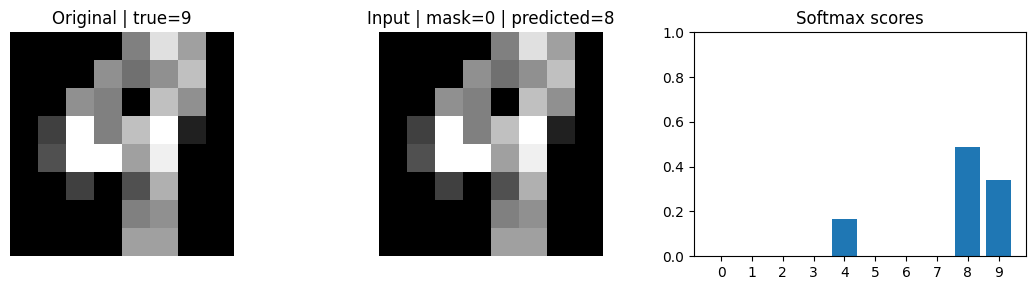

Dataset index: 677
Correct: False


In [27]:
success_positions = np.flatnonzero(clean_pred == test_labels)

if len(success_positions):
    print("Success example")
    demo(int(success_positions[0]), mask_size=0)

failure_found = False

# เลือกข้อผิดพลาดตัวแรกตามลำดับเงื่อนไขที่กำหนดไว้
for size in cfg["occlusion_sizes"]:
    predictions = cnn_predict(occlude(test_images, size))
    wrong_positions = np.flatnonzero(predictions != test_labels)

    if len(wrong_positions):
        position = int(wrong_positions[0])

        print("Failure example")
        print("Mask size:", size)
        demo(position, mask_size=size)

        failure_found = True
        break

if not failure_found:
    print(
        "No failure found in the predefined conditions. "
        "Report this honestly; do not invent a failure."
    )

In [28]:
import shutil

shutil.make_archive(
    "missing_digit_results",
    "zip",
    root_dir="results"
)

from google.colab import files
files.download("missing_digit_results.zip")
files.download("config.json")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>